# 05 - When the model fails: diagnosing the decay and adding a second decision point

**The story in five steps:** (1) the approval-time model decays in July-August; (2) the obvious fixes
(retrain monthly, drop calendar features) do not help; (3) a diagnosis points at a sudden local shock
that outcome history cannot see in time; (4) a second score at *carrier handover* can; (5) it holds up -
with caveats about what the test months can and cannot prove.

All numbers are read from generated files (`rolling_backtest.json`, `stage2_results.json`,
`drift_status.csv`); nothing is typed by hand. Inferences are computed.

In [1]:
import warnings

warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from ontime.config import load_config, project_path

REP = project_path(load_config()["paths"]["reports_dir"])
rj = lambda n: json.loads((REP / n).read_text("utf-8"))
res, roll, s2 = rj("results.json"), rj("rolling_backtest.json"), rj("stage2_results.json")
pct = lambda v: f"{v:.1%}"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The symptom
The deployed approval-time model (logistic regression) ranks well in the first months and then decays.

In [2]:
m = pd.DataFrame(res["monthly"])
m = m[m["model"] == res["primary_model"]].sort_values("month")
display(m[["month", "orders", "late_rate", "roc_auc", "lift_at_10"]].set_index("month"))
Markdown(f"""
**Inference.** ROC-AUC goes from **{m.iloc[0]["roc_auc"]:.2f}** ({m.iloc[0]["month"]}) to
**{m.iloc[-1]["roc_auc"]:.2f}** ({m.iloc[-1]["month"]}) and lift at 10% capacity from
**{m.iloc[0]["lift_at_10"]:.2f}** to **{m.iloc[-1]["lift_at_10"]:.2f}** (1.0 = random).
""")

,orders,late_rate,roc_auc,lift_at_10
month,,,,
2018-05,6940,0.065,0.746,2.828
2018-06,6094,0.012,0.776,3.159
2018-07,6021,0.032,0.639,2.583
2018-08,5038,0.075,0.566,1.069



**Inference.** ROC-AUC goes from **0.75** (2018-05) to
**0.57** (2018-08) and lift at 10% capacity from
**2.83** to **1.07** (1.0 = random).


## 2. The cheap fixes (a rolling-origin backtest)
Hypothesis A: the model is stale, so **retrain every month** on all outcomes known by then.
Hypothesis B: calendar features (`approve_month`, holiday features) encode "which part of the year the
data covered" and hurt out of time, so **drop them**. Both tested against the static model, month by
month, February-August 2018. This is a *development* backtest: those months had already been seen.

In [3]:
rows = []
for v in roll["summary"].values():
    d = v.get("lift_diff_vs_static")
    rows.append(
        {
            "variant": v["label"],
            "macro ROC-AUC": v["macro_roc_auc"],
            "pooled lift@10%": v["pooled_lift_at_10"],
            "lift diff vs static": d["diff"] if d else np.nan,
            "CI low": d["ci95"][0] if d else np.nan,
            "CI high": d["ci95"][1] if d else np.nan,
        }
    )
tbl = pd.DataFrame(rows).set_index("variant")
display(tbl)
lr = roll["summary"]["retrain_logreg_full"]["lift_diff_vs_static"]
ab = roll["proxy_ablation"]
Markdown(f"""
**Inference.**
- **Retraining did not help:** lift difference **{lr["diff"]:+.2f}**, 95% CI [{lr["ci95"][0]:+.2f}, {lr["ci95"][1]:+.2f}].
  The decay is not staleness.
- **Dropping the calendar proxies did not help either:** logistic regression
  {ab["logreg"]["noproxy_minus_full_lift"]:+.2f} [{ab["logreg"]["ci95"][0]:+.2f}, {ab["logreg"]["ci95"][1]:+.2f}],
  LightGBM {ab["lgbm"]["noproxy_minus_full_lift"]:+.2f} [{ab["lgbm"]["ci95"][0]:+.2f}, {ab["lgbm"]["ci95"][1]:+.2f}].
  An earlier suggestion in this project to remove them is **retracted**.
- Negative results are results: they rule out the cheap explanations.
""")

,macro ROC-AUC,pooled lift@10%,lift diff vs static,CI low,CI high
variant,,,,,
"Deployed v1 (trained once, to Jan 2018)",0.710,2.373,NaN,NaN,NaN
"Logistic regression, monthly retrain, all features",0.703,2.340,-0.032,-0.102,0.035
"Logistic regression, monthly retrain, no calendar proxies",0.690,2.303,-0.070,-0.140,0.005
"LightGBM, monthly retrain, all features",0.639,1.820,-0.553,-0.699,-0.405
"LightGBM, monthly retrain, no calendar proxies",0.616,1.723,-0.650,-0.789,-0.491



**Inference.**
- **Retraining did not help:** lift difference **-0.03**, 95% CI [-0.10, +0.04].
  The decay is not staleness.
- **Dropping the calendar proxies did not help either:** logistic regression
  -0.04 [-0.10, +0.02],
  LightGBM -0.10 [-0.19, +0.00].
  An earlier suggestion in this project to remove them is **retracted**.
- Negative results are results: they rule out the cheap explanations.


## 3. The diagnosis
If it is not staleness, something *changed*. Let us look at where the lateness moved in the last month,
and at whether outcome-based history still pointed the right way.

In [4]:
from sklearn.metrics import roc_auc_score

f = pd.read_parquet(project_path(load_config()["paths"]["features_parquet"]))
f["month"] = f["approved_at"].dt.strftime("%Y-%m")
last = sorted(f.loc[f["split"] == "test", "month"].unique())[-1]
prev = sorted(f.loc[f["split"] == "test", "month"].unique())[:-1]
a = f[f["month"] == last]
b = f[f["month"].isin(prev)]
st = pd.DataFrame(
    {
        "orders in last month": a.groupby("customer_state").size(),
        "late rate, last month": a.groupby("customer_state")["is_late"].mean(),
        "late rate, earlier test months": b.groupby("customer_state")["is_late"].mean(),
    }
).dropna()
st["change (pp)"] = (st["late rate, last month"] - st["late rate, earlier test months"]) * 100
st["share of last month's orders"] = st["orders in last month"] / st["orders in last month"].sum()
st["contribution to the rise (pp)"] = st["change (pp)"] * st["share of last month's orders"]
top = (
    st[st["orders in last month"] >= 100]
    .sort_values("contribution to the rise (pp)", ascending=False)
    .head(4)
)
display(top)
auc_hist = roc_auc_score(
    a["is_late"],
    a["customer_state_late_rate_shrunk"].fillna(a["customer_state_late_rate_shrunk"].median()),
)
worst = top.index[0]
Markdown(f"""
**Inference.**
- The state that contributes most to the rise (change x share of orders, among states with 100+ orders)
  is **{worst}**: {pct(top.iloc[0]["late rate, earlier test months"])} -> **{pct(top.iloc[0]["late rate, last month"])}**
  ({top.iloc[0]["change (pp)"]:+.1f} pp), and {worst} is **{top.iloc[0]["share of last month's orders"]:.0%}** of the month's orders.
  The table shows the top four by that contribution.
- The all-time customer-state late-rate feature has AUC **{auc_hist:.2f}** against the outcome in {last}
  ({"worse than random: history points the wrong way" if auc_hist < 0.5 else "better than random"}).
- Outcome history only updates when parcels are *delivered*, roughly 10+ days after the decision, so at
  approval time a fresh shock is invisible.
""")

,orders in last month,"late rate, last month","late rate, earlier test months",change (pp),share of last month's orders,contribution to the rise (pp)
customer_state,,,,,,
SP,"2,373.000",0.115,0.029,8.637,0.471,4.068
RJ,575.000,0.070,0.037,3.276,0.114,0.374
RS,257.000,0.035,0.020,1.531,0.051,0.078
PR,262.000,0.042,0.030,1.194,0.052,0.062



**Inference.**
- The state that contributes most to the rise (change x share of orders, among states with 100+ orders)
  is **SP**: 2.9% -> **11.5%**
  (+8.6 pp), and SP is **47%** of the month's orders.
  The table shows the top four by that contribution.
- The all-time customer-state late-rate feature has AUC **0.34** against the outcome in 2018-08
  (worse than random: history points the wrong way).
- Outcome history only updates when parcels are *delivered*, roughly 10+ days after the decision, so at
  approval time a fresh shock is invisible.


## 4. A second decision point
The seller hands the parcel to the carrier within ~1-2 days of approval - long before delivery and
well before the promised date. At that moment we know:

| New signal at handover | Why it helps |
|---|---|
| Own handover timing (days to handover, vs the seller's shipping limit, promise days left) | seller-side delays are visible |
| Seller's recent handover punctuality | fast-moving seller state (outcome-free, short delay) |
| **Destination backlog**: of earlier orders to the same state handed over 8-28 days ago, share *still undelivered today* | rises while a regional problem builds, before delivered outcomes arrive |

**Leakage discipline kept:** customer delivery date and reviews never used; a delivery counts only if it
happened on a day *before* the decision day; backlog events come from **all** orders (not only those that
were later delivered). Tests: future deliveries must not change the feature; vectorized == brute-force loop.

In [5]:
t = s2["test"]
m1, m2 = t["stage1"]["metrics"], t["stage2"]["metrics"]
k1 = next(x for x in t["stage1"]["top_k"] if abs(x["k"] - 0.1) < 1e-9)
k2 = next(x for x in t["stage2"]["top_k"] if abs(x["k"] - 0.1) < 1e-9)
cmp = pd.DataFrame(
    {
        "stage 1 (at approval)": [
            m1["pr_auc"]["value"],
            m1["roc_auc"]["value"],
            k1["lift"],
            k1["precision"],
            k1["recall"],
        ],
        "stage 2 (at handover)": [
            m2["pr_auc"]["value"],
            m2["roc_auc"]["value"],
            k2["lift"],
            k2["precision"],
            k2["recall"],
        ],
    },
    index=["PR-AUC", "ROC-AUC", "lift @10%", "precision @10%", "recall @10%"],
)
display(cmp)
d = t["pr_auc_diff_stage2_minus_stage1"]
ld = t["lift_at_10_diff_stage2_minus_stage1"]
Markdown(f"""
**Inference.** On the same {s2["population"]["test"]:,} test orders: PR-AUC **{m1["pr_auc"]["value"]:.3f} -> {m2["pr_auc"]["value"]:.3f}**
(paired difference {d["diff"]:+.3f}, 95% CI [{d["ci95"][0]:+.3f}, {d["ci95"][1]:+.3f}]); lift at 10% capacity
**{k1["lift"]:.1f}x -> {k2["lift"]:.1f}x** (difference {ld["diff"]:+.2f}, CI [{ld["ci95"][0]:+.2f}, {ld["ci95"][1]:+.2f}]).
Base rate is {t["late_rate"]:.3f}.
""")

,stage 1 (at approval),stage 2 (at handover)
PR-AUC,0.093,0.395
ROC-AUC,0.701,0.826
lift @10%,2.363,4.592
precision @10%,0.107,0.209
recall @10%,0.241,0.468



**Inference.** On the same 24,093 test orders: PR-AUC **0.093 -> 0.395**
(paired difference +0.302, 95% CI [+0.271, +0.330]); lift at 10% capacity
**2.4x -> 4.6x** (difference +2.23, CI [+1.55, +2.86]).
Base rate is 0.045.


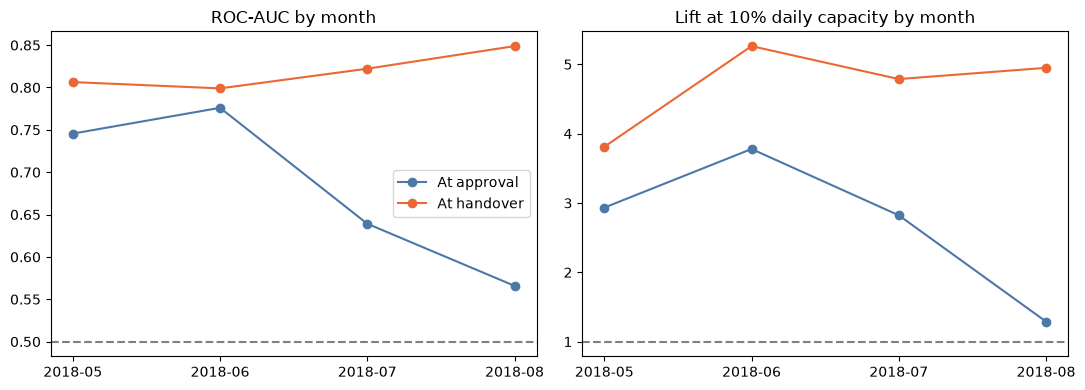


**Inference.** In **2018-08** (the month stage 1 collapsed) stage 2 reaches ROC-AUC
**0.85** vs **0.57** at approval.
The decay is gone because the model can now *see* the backlog building.


In [6]:
mm = pd.DataFrame(t["monthly"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for col, lab, c in [("stage1", "At approval", "#4C78A8"), ("stage2", "At handover", "#EB6834")]:
    ax[0].plot(mm["month"], mm[f"{col}_roc_auc"], "o-", color=c, label=lab)
    ax[1].plot(mm["month"], mm[f"{col}_lift_at_10"], "o-", color=c, label=lab)
ax[0].axhline(0.5, color="grey", ls="--")
ax[0].set_title("ROC-AUC by month")
ax[0].legend()
ax[1].axhline(1.0, color="grey", ls="--")
ax[1].set_title("Lift at 10% daily capacity by month")
plt.tight_layout()
plt.show()
Markdown(f"""
**Inference.** In **{mm.iloc[-1]["month"]}** (the month stage 1 collapsed) stage 2 reaches ROC-AUC
**{mm.iloc[-1]["stage2_roc_auc"]:.2f}** vs **{mm.iloc[-1]["stage1_roc_auc"]:.2f}** at approval.
The decay is gone because the model can now *see* the backlog building.
""")

## 5. Is it too good to be true? Three checks
1. **Ablation** (validation period only, logistic regression): what does each block add?
2. **Within-group discrimination:** if the backlog encoded each order's own outcome it would separate late
   from on-time orders even *within* one state-month. It should not.
3. **Time to act:** a prediction is only useful if there is time left.

In [7]:
ab = pd.DataFrame(s2["ablation_validation_logreg"]).T
display(ab)
w = s2["backlog_within_state_month"]
win = t["action_window_for_late_orders"]
gain_t = ab.loc["+ own handover timing", "pr_auc"] - ab.loc["stage-1 features only", "pr_auc"]
gain_b = ab.loc["+ destination backlog", "pr_auc"] - ab.loc["stage-1 features only", "pr_auc"]
gain_all = ab.loc["all stage-2 features", "pr_auc"] - ab.loc["stage-1 features only", "pr_auc"]
Markdown(f"""
**Inference.**
- **Complementary signals:** handover timing adds **{gain_t:+.3f}** PR-AUC, the backlog **{gain_b:+.3f}**, together
  **{gain_all:+.3f}**. The seller handover history alone adds nothing ({ab.loc["+ seller handover history", "pr_auc"]:.3f} vs
  {ab.loc["stage-1 features only", "pr_auc"]:.3f}) and is kept only because it was pre-declared.
- **Not an outcome leak:** the backlog's median AUC within a single state-month is only **{w["median_auc"]:.2f}**
  over {w["groups"]} groups: it says *when and where* trouble is, not *which order* is late.
- **Time left:** handover happens a median **{win["median_days_to_handover"]:.1f}** days after approval; late orders
  have a median **{win["median_days_left_at_handover"]:.0f}** days before the promised date, and
  **{win["share_with_3plus_days_left"]:.0%}** have 3 or more.
""")

,pr_auc,roc_auc
stage-1 features only,0.259,0.716
+ own handover timing,0.348,0.744
+ seller handover history,0.243,0.698
+ destination backlog,0.311,0.757
all stage-2 features,0.397,0.788



**Inference.**
- **Complementary signals:** handover timing adds **+0.089** PR-AUC, the backlog **+0.053**, together
  **+0.139**. The seller handover history alone adds nothing (0.243 vs
  0.259) and is kept only because it was pre-declared.
- **Not an outcome leak:** the backlog's median AUC within a single state-month is only **0.53**
  over 18 groups: it says *when and where* trouble is, not *which order* is late.
- **Time left:** handover happens a median **1.2** days after approval; late orders
  have a median **10** days before the promised date, and
  **70%** have 3 or more.


## 6. What this does and does not prove
**Does:** the failure was a *visibility* problem, not a modelling one; a later decision point plus a
signal designed for the failure removes it, with leakage tests and an ablation behind it.

**Does not:**
- It is **not a clean hold-out.** The test months had already been used once to evaluate stage 1. Stage 2
  was pre-declared (selection by validation, one test scoring, paired comparison), but confirmation needs
  new data.
- It is a **ranking**, not calibrated probabilities.
- Interventions at handover have **less time** than at approval, and some may no longer be possible.
- The policy numbers are a **simulation** with an assumed success rate.

**Next:** fresh data to confirm; stage-2 calibration and reason codes in the app; a randomized pilot.